# 01 · Daily runs and incidents

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/b2b-saas-data-platforms/saas-revenue-elt/notebooks/01_daily_runs_and_incidents.ipynb)

A client runs a B2B SaaS product. Revenue data sits in three places: a CRM database (accounts, subscriptions), a billing REST API (invoices) and daily NDJSON files from the product team (usage events). This notebook runs the full pipeline once a day for a simulated quarter, from an initial load on 30 June 2026 to 30 September, and shows what happened on the days something went wrong.

Six incidents are planted on purpose: a paging bug in the API, a new field nobody announced, an invalid value in the CRM, a negative invoice, broken lines in an event file and a warehouse outage. Late and duplicated events happen every day.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "b2b-saas-data-platforms/saas-revenue-elt"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "saas_elt").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import logging, shutil
logging.basicConfig(level=logging.ERROR)
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: saas-revenue-elt


## Run 93 days

Each day the simulator changes the source systems, then the DAG extracts, validates, loads, transforms, tests and reconciles. Takes about half a minute.

In [2]:
from saas_elt import config
from saas_elt.pipeline import run_simulation
from saas_elt import reporting

workdir = Path("workdir/notebook_run")
if workdir.exists():
    shutil.rmtree(workdir)
sim = run_simulation(config.RunSettings(workdir=workdir), progress=True)
wh = sim.warehouse
q = lambda sql: pd.read_sql_query(sql, wh.conn)
print(f"{len(sim.runs)} daily runs, {sum(r.status == 'success' for r in sim.runs)} successful")

2026-07-01: success
2026-07-16: success
2026-07-31: success
2026-08-15: success
2026-08-30: success
2026-09-13: failed (transform, test, reconcile, housekeeping, publish)
2026-09-14: success
2026-09-29: success
93 daily runs, 92 successful


In [3]:
status = reporting.run_status(sim)
status[status["status"] != "success"]

,run_date,status,failed_tasks
75,2026-09-13,failed,"transform, test, reconcile, housekeeping, publish"


## What went wrong, and what the pipeline did

Each row pairs a planted incident with the evidence it left in the metadata tables. None of them stopped the business numbers from being right: the outage day failed loudly and the next run caught up.

In [4]:
reporting.incident_log(sim)

,date,incident,how it was handled,evidence
0,2026-07-20,api_page_overlap,"De-duplicated on (invoice_id, updated_at); control count reconciled",API returned 29 records for 28 changed invoices (1 repeated across pages); 10 already-...
1,2026-08-04,schema_drift,"Records kept, extra field stored in _extra_json, drift logged for a contract update",New field(s) ['discount_eur'] first seen in batch billing_invoices:2026-08-04
2,2026-08-19,bad_segment_value,Contract enum check; dashboards kept the last valid segment,1 account record quarantined; corrected version loaded the next day
3,2026-08-29,negative_invoice,Contract min-value check; invoice reconciliation explains the difference,1 invoice quarantined; August EUR total reconciles with the gap fully explained
4,2026-09-08,malformed_event_lines,Rest of the file loaded; other files unaffected,"5 broken line(s) quarantined by file and line number, content not stored"
5,2026-09-13,transform_outage,"Retries, then fail fast; next day's run rebuilt the models from raw and caught up",transform failed 3 attempts; downstream tasks skipped; next run's MRR check: pass
6,every day,late and duplicate events,Load-time de-duplication on event_id; 3-day look-back in the incremental usage model,"2,438 events arrived 1 to 2 days late; 323 duplicates dropped"


## Daily loads

Red dots mark days with quarantined records.

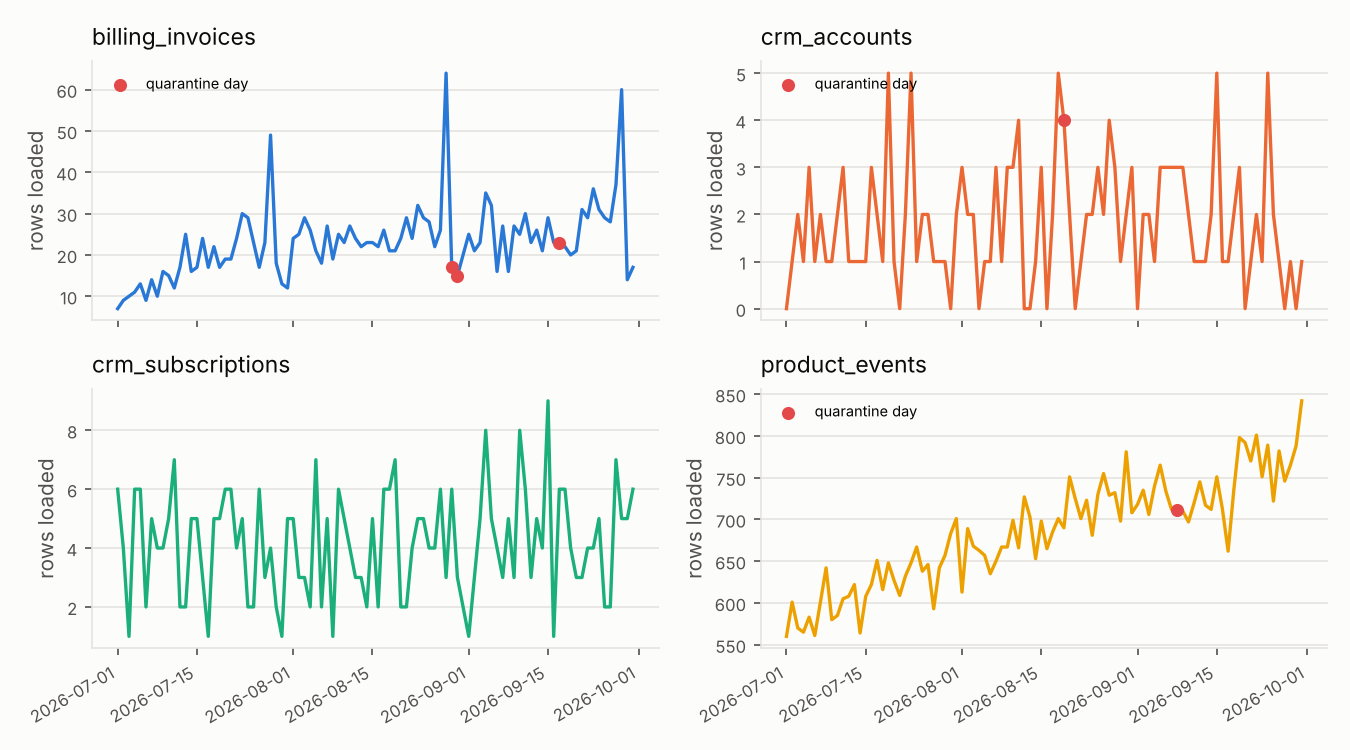

,run_date,source,extracted,loaded,quarantined,duplicates_skipped,control_count
80,2026-07-20,billing_invoices,29,19,0,10,28.0
81,2026-07-20,crm_accounts,1,1,0,0,1.0
82,2026-07-20,crm_subscriptions,6,6,0,0,6.0
83,2026-07-20,product_events,631,627,0,4,NaN


In [5]:
display(Image(filename=str(reporting.plot_daily_loads(sim, Path("outputs/figures/daily_loads.png")))))
reporting.daily_loads(sim).query("run_date == '2026-07-20'")

## The quarantine

Records that break their contract never reach the raw tables. They wait here with the reasons. Personal data would be masked before landing here, and broken event lines are stored by file and line number only, because their content could be anything.

In [6]:
q("SELECT run_date, source, record_key, reasons, substr(payload_json, 1, 80) AS payload FROM meta_quarantine")

,run_date,source,record_key,reasons,payload
0,2026-08-19,crm_accounts,ACC-00018,not_in_enum: segment='Mid-Market',"{""account_id"": ""ACC-00018"", ""company_name"": ""Elblicht SAS"", ""country"": ""NL"", ""cr"
1,2026-08-29,billing_invoices,INV-000736,below_min: amount_net=-295.0 < 0; below_min: amount_gross=-351.05 < 0,"{""account_id"": ""ACC-00004"", ""amount_gross"": -351.05, ""amount_net"": -295.0, ""curr"
2,2026-08-30,billing_invoices,INV-000736,below_min: amount_net=-295.0 < 0; below_min: amount_gross=-351.05 < 0,"{""account_id"": ""ACC-00004"", ""amount_gross"": -351.05, ""amount_net"": -295.0, ""curr"
3,2026-09-08,product_events,NaN,malformed_json: events_2026-09-08.ndjson line 380,"{""file"": ""events_2026-09-08.ndjson"", ""length"": 102, ""line"": 380}"
4,2026-09-08,product_events,NaN,malformed_json: events_2026-09-08.ndjson line 432,"{""file"": ""events_2026-09-08.ndjson"", ""length"": 102, ""line"": 432}"
5,2026-09-08,product_events,NaN,malformed_json: events_2026-09-08.ndjson line 555,"{""file"": ""events_2026-09-08.ndjson"", ""length"": 97, ""line"": 555}"
6,2026-09-08,product_events,NaN,malformed_json: events_2026-09-08.ndjson line 633,"{""file"": ""events_2026-09-08.ndjson"", ""length"": 101, ""line"": 633}"
7,2026-09-08,product_events,NaN,malformed_json: events_2026-09-08.ndjson line 715,"{""file"": ""events_2026-09-08.ndjson"", ""length"": 97, ""line"": 715}"
8,2026-09-17,billing_invoices,INV-000736,below_min: amount_net=-295.0 < 0; below_min: amount_gross=-351.05 < 0,"{""account_id"": ""ACC-00004"", ""amount_gross"": -351.05, ""amount_net"": -295.0, ""curr"


In [7]:
q("SELECT * FROM meta_schema_drift")

,source,field,first_seen_batch,first_seen_at
0,billing_invoices,discount_eur,billing_invoices:2026-08-04,2026-11-17T20:58:44+00:00


## The outage day

The transform task failed three times (one try plus two retries). Tests, reconciliation and publishing were skipped instead of running on stale tables. The next morning's run rebuilt everything from the raw layer.

In [8]:
q("SELECT run_date, task, attempt, status, message FROM meta_task_runs WHERE run_date IN ('2026-09-13', '2026-09-14') AND task IN ('transform', 'publish', 'reconcile')")

,run_date,task,attempt,status,message
0,2026-09-13,transform,1,failed,RuntimeError: model fct_mrr_daily failed: simulated outage while building fct_mrr_daily
1,2026-09-13,transform,2,failed,RuntimeError: model fct_mrr_daily failed: simulated outage while building fct_mrr_daily
2,2026-09-13,transform,3,failed,RuntimeError: model fct_mrr_daily failed: simulated outage while building fct_mrr_daily
3,2026-09-13,reconcile,0,upstream_failed,skipped
4,2026-09-13,publish,0,upstream_failed,skipped
5,2026-09-14,transform,1,success,
6,2026-09-14,reconcile,1,success,
7,2026-09-14,publish,1,success,
